# De píxeles a patrones
### Histogramas · Convolución · Aprendizaje por gradientes

Una imagen es una matriz de intensidades. Un histograma resume sus cantidades, un filtro examina su distribución y el aprendizaje ajusta parámetros para reducir errores.

Las figuras se generan con Python y el sistema de visualización incluido en Jupyter. No se necesitan NumPy, Matplotlib, descargas ni datos externos.

## Preparación visual

Estas funciones dibujan las matrices y las gráficas. Los cálculos del ejemplo aparecen en las siguientes secciones.

In [1]:
from IPython.display import SVG, display
from html import escape
from math import log10

def texto(x, y, valor, tam=16, color="#243247", centro=False):
    ancla = "middle" if centro else "start"
    return f'<text x="{x}" y="{y}" font-size="{tam}" fill="{color}" text-anchor="{ancla}">{escape(str(valor))}</text>'

def figura(contenido, ancho=900, alto=330):
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" width="{ancho}" height="{alto}" viewBox="0 0 {ancho} {alto}" role="img"><rect width="100%" height="100%" fill="#f8fafc"/><g font-family="Arial, sans-serif">{contenido}</g></svg>'))

def matriz(datos, x, y, titulo, lado=42, tipo="binaria", ventana=None, casilla=None):
    dibujo = texto(x, y - 18, titulo, 18)
    for i, fila in enumerate(datos):
        for j, valor in enumerate(fila):
            if tipo == "binaria":
                fondo, tinta = ("#ffffff", "#111827") if valor else ("#182536", "#ffffff")
            else:
                fondo = "#e9eef4" if valor == 0 else ("#c7e5ff" if valor > 0 else "#ffdbb8")
                tinta = "#182536"
            px, py = x + j * lado, y + i * lado
            dibujo += f'<rect x="{px}" y="{py}" width="{lado}" height="{lado}" fill="{fondo}" stroke="#91a0b3"/>'
            dibujo += texto(px + lado / 2, py + lado / 2 + 6, valor, 18, tinta, True)
    for posicion, tamaño in [(ventana, 3), (casilla, 1)]:
        if posicion is not None:
            i, j = posicion
            dibujo += f'<rect x="{x+j*lado+2}" y="{y+i*lado+2}" width="{tamaño*lado-4}" height="{tamaño*lado-4}" fill="none" stroke="#a21caf" stroke-width="4"/>'
    return dibujo

def barras(valores, x, y, titulo):
    dibujo = texto(x, y - 22, titulo, 18)
    for i, (nombre, valor) in enumerate(zip(["Negros (0)", "Blancos (1)"], valores)):
        py = y + i * 72
        dibujo += texto(x, py + 18, nombre, 15)
        dibujo += f'<rect x="{x+95}" y="{py}" width="{valor*10}" height="28" fill="#167d9a" rx="3"/>'
        dibujo += texto(x + 105 + valor * 10, py + 20, valor)
    return dibujo + texto(x + 95, y + 157, "Cantidad de píxeles", 14)

def curva(valores, x, y, titulo, log=False):
    ancho, alto = 320, 170
    v = [log10(a) for a in valores] if log else valores
    minimo, maximo = (min(v), 0) if log else (0, 1.1)
    puntos = [(x + i * ancho / (len(v)-1), y + alto - (a-minimo)/(maximo-minimo)*alto) for i,a in enumerate(v)]
    dibujo = texto(x, y - 34, titulo, 18)
    ticks = [0, -2, -4, -6, -8] if log else [0, 0.5, 1]
    for t in ticks:
        py = y + alto - (t-minimo)/(maximo-minimo)*alto
        dibujo += f'<line x1="{x}" y1="{py}" x2="{x+ancho}" y2="{py}" stroke="#cbd5e1"/>'
        dibujo += texto(x - 10, py + 5, f"1e{t}" if log else t, 12, centro=True)
    cadena = " ".join(f"{px},{py}" for px,py in puntos)
    dibujo += f'<polyline points="{cadena}" fill="none" stroke="#167d9a" stroke-width="3"/>'
    for i,(px,py) in enumerate(puntos):
        dibujo += f'<circle cx="{px}" cy="{py}" r="5" fill="#167d9a"/>'
        dibujo += texto(px, y + alto + 24, i, 13, centro=True)
    return dibujo + texto(x + ancho/2, y + alto + 52, "Iteración", 14, centro=True)


## 1. Una imagen es una matriz

El **0 representa negro** y el **1 representa blanco**. La distribución de estos 25 píxeles forma un siete. Cambiar el orden de las filas cambia el dibujo.

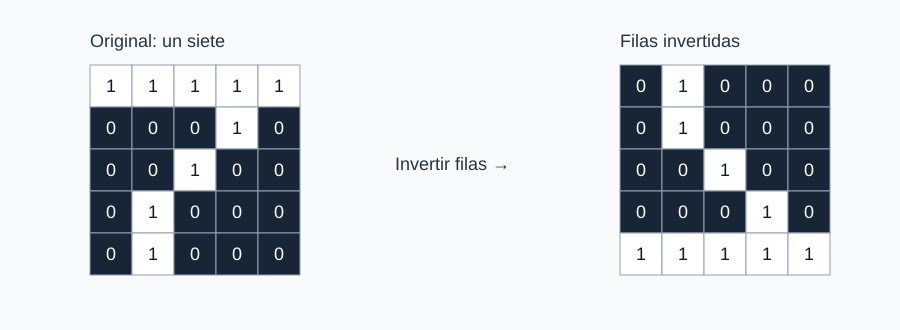

In [2]:
imagen = [
    [1, 1, 1, 1, 1],
    [0, 0, 0, 1, 0],
    [0, 0, 1, 0, 0],
    [0, 1, 0, 0, 0],
    [0, 1, 0, 0, 0],
]
invertida = imagen[::-1]

figura(
    matriz(imagen, 90, 65, "Original: un siete")
    + texto(395, 170, "Invertir filas →", 18)
    + matriz(invertida, 620, 65, "Filas invertidas")
)

## 2. El histograma cuenta colores

Las dos imágenes contienen **16 píxeles negros y 9 blancos**. Por eso tienen el mismo histograma, aunque sus formas son distintas. Es como contar piezas LEGO por color: las cantidades no indican cómo están acomodadas.

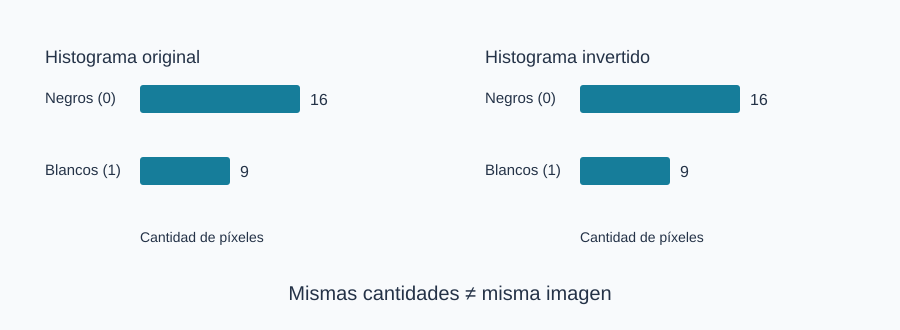

In [3]:
def histograma(imagen):
    conteo = [0, 0]
    for fila in imagen:
        for pixel in fila:
            conteo[pixel] += 1
    return conteo

figura(
    barras(histograma(imagen), 45, 85, "Histograma original")
    + barras(histograma(invertida), 485, 85, "Histograma invertido")
    + texto(450, 300, "Mismas cantidades ≠ misma imagen", 20, centro=True)
)

## 3. Un filtro compara posiciones

El kernel resta la columna izquierda, ignora el centro y suma la derecha. Multiplicamos cada píxel por su peso y sumamos los productos.

Esta región es un ejemplo aislado de borde. Cada fila aporta `0×(−1) + 0×0 + 1×1 = 1`. La respuesta total es **3**.

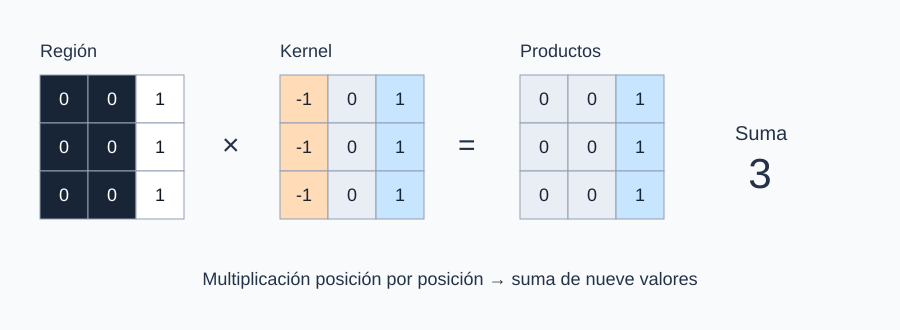

In [4]:
region = [[0, 0, 1], [0, 0, 1], [0, 0, 1]]
kernel = [[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]]

def aplicar_filtro(region, kernel):
    total = 0
    for i in range(3):
        for j in range(3):
            total += region[i][j] * kernel[i][j]
    return total

productos = [[region[i][j] * kernel[i][j] for j in range(3)] for i in range(3)]
figura(
    matriz(region, 40, 75, "Región", lado=48)
    + texto(222, 155, "×", 30)
    + matriz(kernel, 280, 75, "Kernel", lado=48, tipo="respuesta")
    + texto(458, 155, "=", 30)
    + matriz(productos, 520, 75, "Productos", lado=48, tipo="respuesta")
    + texto(735, 140, "Suma", 20)
    + texto(760, 188, aplicar_filtro(region, kernel), 42, centro=True)
    + texto(450, 285, "Multiplicación posición por posición → suma de nueve valores", 18, centro=True)
)

Una respuesta **positiva** indica más intensidad a la derecha; una **negativa**, más intensidad a la izquierda. Una respuesta **cero** significa que las sumas se compensan, como en una región uniforme. El resultado no es una probabilidad ni un dígito reconocido.

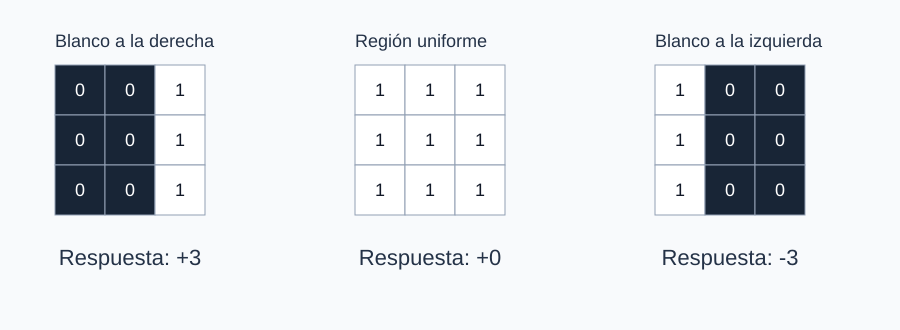

In [5]:
regiones = [region, [[1, 1, 1]] * 3, [[1, 0, 0]] * 3]
nombres = ["Blanco a la derecha", "Región uniforme", "Blanco a la izquierda"]
dibujo = ""
for i, (bloque, nombre) in enumerate(zip(regiones, nombres)):
    x = 55 + i * 300
    dibujo += matriz(bloque, x, 65, nombre, lado=50)
    dibujo += texto(x + 75, 265, f"Respuesta: {aplicar_filtro(bloque, kernel):+d}", 22, centro=True)
figura(dibujo)

## 4. Deslizar el filtro: de imagen a mapa

En cada posición extraemos una ventana de 3×3, aplicamos el mismo filtro y guardamos una respuesta. Una imagen de 5×5 produce un mapa de **3×3**, porque `5 − 3 + 1 = 3` posiciones caben en cada dimensión. Avanzamos un píxel por paso, sin añadir relleno.

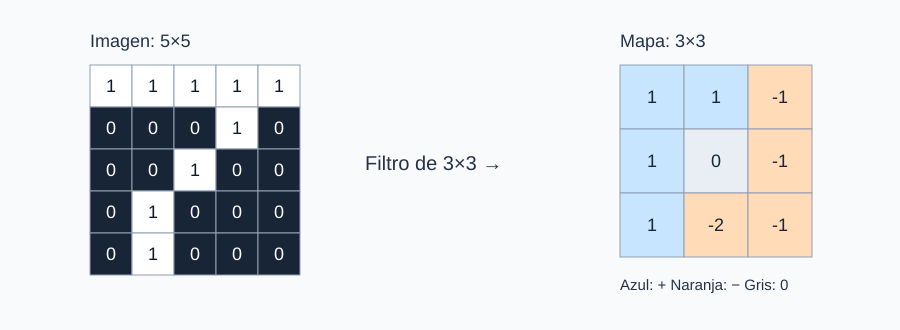

In [6]:
def convolucion(imagen, kernel):
    mapa = []
    for fila in range(len(imagen) - 2):
        fila_salida = []
        for columna in range(len(imagen[0]) - 2):
            ventana = [r[columna:columna + 3] for r in imagen[fila:fila + 3]]
            fila_salida.append(aplicar_filtro(ventana, kernel))
        mapa.append(fila_salida)
    return mapa

mapa = convolucion(imagen, kernel)
figura(
    matriz(imagen, 90, 65, "Imagen: 5×5")
    + texto(365, 170, "Filtro de 3×3 →", 20)
    + matriz(mapa, 620, 65, "Mapa: 3×3", lado=64, tipo="respuesta")
    + texto(620, 290, "Azul: +    Naranja: −    Gris: 0", 15)
)

### Una ventana y su respuesta

El marco morado relaciona la región de entrada con su casilla en el mapa. `fila` y `columna` pueden valer **0, 1 o 2**; al cambiarlas y ejecutar la celda, se actualizan la ventana, los productos y el resultado.

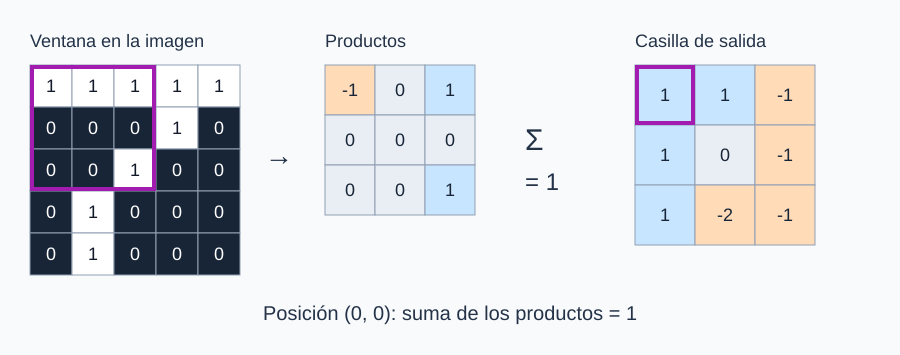

In [7]:
fila, columna = 0, 0
assert 0 <= fila <= 2 and 0 <= columna <= 2
ventana = [r[columna:columna + 3] for r in imagen[fila:fila + 3]]
productos = [[ventana[i][j] * kernel[i][j] for j in range(3)] for i in range(3)]
respuesta = aplicar_filtro(ventana, kernel)

figura(
    matriz(imagen, 30, 65, "Ventana en la imagen", ventana=(fila, columna))
    + texto(265, 165, "→", 28)
    + matriz(productos, 325, 65, "Productos", lado=50, tipo="respuesta")
    + texto(525, 150, "Σ", 30)
    + texto(525, 190, f"= {respuesta}", 24)
    + matriz(mapa, 635, 65, "Casilla de salida", lado=60, tipo="respuesta", casilla=(fila, columna))
    + texto(450, 320, f"Posición ({fila}, {columna}): suma de los productos = {respuesta}", 20, centro=True),
    alto=355
)

El mapa conserva la ubicación de las respuestas del filtro. Detectar estos contrastes **no equivale a reconocer el siete**: una red combina varias características para clasificar.

Aquí usamos correlación cruzada, porque el kernel no se invierte; en CNN esta operación suele llamarse convolución.

## 5. Ajustar un peso para reducir el error

Hasta ahora el kernel es fijo. Para ilustrar el aprendizaje, usamos su respuesta al borde (**3**) como entrada y ajustamos un peso para obtener una salida cercana a **1**.

`predicción = peso × entrada`  
`error = (predicción − objetivo)²`  
`gradiente = 2 × (predicción − objetivo) × entrada`  
`peso nuevo = peso − paso × gradiente`

El gradiente es la pendiente del error respecto al peso. El tamaño del paso controla cuánto se modifica el peso.

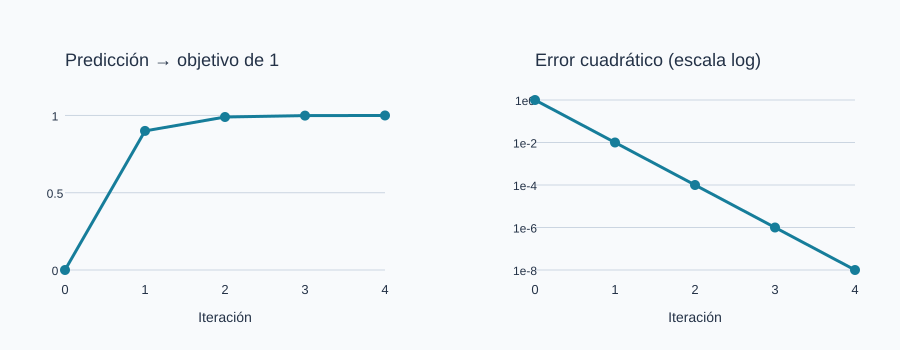

Iteración   Peso       Predicción   Error
        0   0.000000   0.000000     1.00000000
        1   0.300000   0.900000     0.01000000
        2   0.330000   0.990000     0.00010000
        3   0.333000   0.999000     0.00000100
        4   0.333300   0.999900     0.00000001


In [8]:
entrada, objetivo = aplicar_filtro(region, kernel), 1
peso, paso = 0.0, 0.05
historial = []

for iteracion in range(5):
    prediccion = peso * entrada
    error = (prediccion - objetivo) ** 2
    historial.append((peso, prediccion, error))
    gradiente = 2 * (prediccion - objetivo) * entrada
    peso -= paso * gradiente

predicciones = [p for _, p, _ in historial]
errores = [e for _, _, e in historial]
figura(
    curva(predicciones, 65, 100, "Predicción → objetivo de 1")
    + curva(errores, 535, 100, "Error cuadrático (escala log)", log=True),
    alto=350
)
print("Iteración   Peso       Predicción   Error")
for i, (w, p, e) in enumerate(historial):
    print(f"{i:9}   {w:.6f}   {p:.6f}     {e:.8f}")

La predicción se acerca a **1** y el error disminuye. La gráfica derecha usa escala logarítmica: cada salto de `1e0` a `1e−2`, por ejemplo, significa un error **100 veces menor**.

En la primera actualización, el gradiente es **−6** y el peso pasa de **0 a 0.3**. La siguiente predicción es **0.9**, con error **0.01**. La tabla muestra los valores antes de cada actualización.

Este ejemplo aprende un peso con un solo dato; no modifica el kernel ni demuestra que el modelo funcione con imágenes nuevas.

## Relación con LeNet-5

Las redes convolucionales combinan respuestas locales en capas sucesivas. Durante el entrenamiento se ajustan numerosos parámetros, incluidos los filtros, usando ejemplos etiquetados. Este notebook ilustra el conteo de intensidades, el filtrado local y una actualización por gradiente; no implementa subsampling ni un clasificador completo.

Referencia: LeCun, Bottou, Bengio y Haffner (1998), [Gradient-Based Learning Applied to Document Recognition](https://proceedingsoftheieee.ieee.org/gradient-based-learning-applied-to-document-recognition/).